# Fecundidad: comparación entre México y Japón

**Estudiante:** Jorge Adalberto Zuñiga Oliva  
**Matrícula:** 82005 · **Grupo:** 512  
**Materia:** Tópicos de Big Data

In [1]:
from pathlib import Path
import sys
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/curso.py").exists())
sys.path.insert(0, str(RAIZ / "scripts"))
from curso import (leer_owid, metadatos, indicador, solo_paises, guardar_figura,
                   guardar_tabla, U1, U3, SALIDA, FUENTES)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.max_rows", 12)
pd.set_option("display.max_columns", 12)

## 1. Pregunta, fuente y unidad
¿Cómo cambió la fecundidad de México y Japón en los mismos años? El indicador es el número
de **nacimientos por mujer** bajo las tasas por edad del periodo; no son nacimientos por mil habitantes.
[OWID: fecundidad](https://ourworldindata.org/grapher/children-born-per-woman).

In [2]:
tabla = indicador("children-born-per-woman", "fertility_rate_hist", "fecundidad")
print("Dimensiones:", tabla.shape)
display(tabla.head())
display(tabla.isna().sum().to_frame("faltantes"))
print("Unidad:", metadatos("children-born-per-woman")["columns"]["fertility_rate_hist"]["unit"])
mexico = tabla.loc[tabla.entity.eq("Mexico")].dropna(subset=["fecundidad"]).sort_values("year")
japon = tabla.loc[tabla.entity.eq("Japan")].dropna(subset=["fecundidad"]).sort_values("year")
print("México:", mexico.shape, "Japón:", japon.shape)

Dimensiones: (19402, 4)


,entity,code,year,fecundidad
0,Afghanistan,AFG,1950,7.248
1,Afghanistan,AFG,1951,7.260
2,Afghanistan,AFG,1952,7.260
3,Afghanistan,AFG,1953,7.266
4,Afghanistan,AFG,1954,7.254


,faltantes
entity,0
code,387
year,0
fecundidad,0


Unidad: live births per woman
México: (74, 4) Japón: (77, 4)


## 2. Alinear los años antes de restar
Dos arreglos de igual longitud podrían representar años diferentes. Por eso se usa una unión
uno a uno por año; la intersección con NumPy verifica el número esperado de coincidencias.

In [3]:
comunes = np.intersect1d(mexico.year.to_numpy(), japon.year.to_numpy())
comparacion = mexico[["year", "fecundidad"]].merge(
    japon[["year", "fecundidad"]], on="year", how="inner",
    suffixes=("_mexico", "_japon"), validate="one_to_one").sort_values("year")
comparacion["diferencia_japon_menos_mexico"] = comparacion.fecundidad_japon - comparacion.fecundidad_mexico
assert len(comparacion) == len(comunes)
display(comparacion.head())
display(comparacion.tail())

,year,fecundidad_mexico,fecundidad_japon,diferencia_japon_menos_mexico
0,1950,6.709,3.615,-3.094
1,1951,6.727,3.225,-3.502
2,1952,6.731,2.947,-3.784
3,1953,6.734,2.673,-4.061
4,1954,6.745,2.468,-4.277


,year,fecundidad_mexico,fecundidad_japon,diferencia_japon_menos_mexico
69,2019,2.02,1.323,-0.697
70,2020,1.99,1.304,-0.686
71,2021,1.97,1.275,-0.695
72,2022,1.94,1.256,-0.684
73,2023,1.91,1.208,-0.702


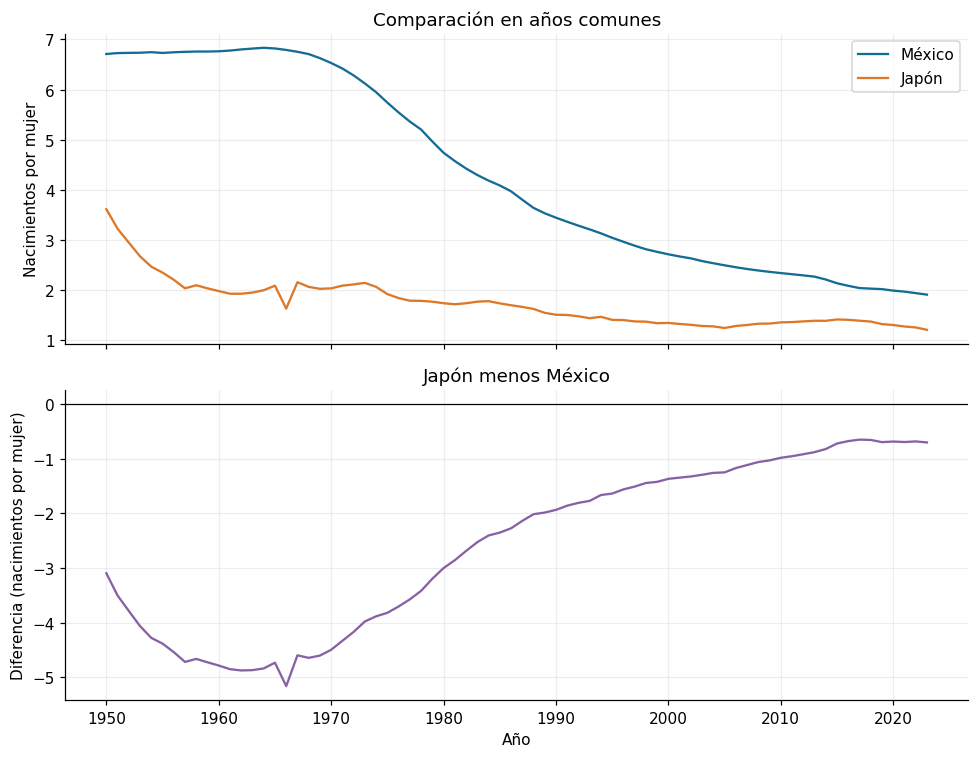

CSV guardado: U1_1_probabilidad_estadistica/data/processed/fecundidad_mexico_japon.csv (74 filas)


In [4]:
fig, ejes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for columna, etiqueta in [("fecundidad_mexico", "México"), ("fecundidad_japon", "Japón")]:
    ejes[0].plot(comparacion.year, comparacion[columna], label=etiqueta)
ejes[0].set(ylabel="Nacimientos por mujer", title="Comparación en años comunes")
ejes[0].legend()
ejes[1].plot(comparacion.year, comparacion.diferencia_japon_menos_mexico, color="#8661a6")
ejes[1].axhline(0, color="black", lw=.8)
ejes[1].set(xlabel="Año", ylabel="Diferencia (nacimientos por mujer)", title="Japón menos México")
guardar_figura("03_fecundidad")
guardar_tabla(comparacion, "fecundidad_mexico_japon.csv", U1 / "data/processed")

In [5]:
resumen = comparacion[["fecundidad_mexico", "fecundidad_japon"]].agg(["mean", "median", "std", "min", "max"])
display(resumen.round(3))
inicio, fin = comparacion.iloc[0], comparacion.iloc[-1]
display(Markdown(f"**Resultado:** se compararon {len(comparacion)} años, de {int(inicio.year)} a {int(fin.year)}. "
    f"En el último año México registra {fin.fecundidad_mexico:.2f} y Japón {fin.fecundidad_japon:.2f} nacimientos por mujer. "
    f"La diferencia Japón − México es {fin.diferencia_japon_menos_mexico:.2f}."))

,fecundidad_mexico,fecundidad_japon
mean,4.326,1.732
median,3.887,1.649
std,1.893,0.469
min,1.910,1.208
max,6.833,3.615


**Resultado:** se compararon 74 años, de 1950 a 2023. En el último año México registra 1.91 y Japón 1.21 nacimientos por mujer. La diferencia Japón − México es -0.70.

## 3. Interpretación
La separación de las curvas cambia con el tiempo; una media de todo el periodo oculta esa evolución.
Una diferencia negativa significa menor fecundidad en Japón. El cruce o la cercanía de curvas
no identifica sus causas: no se han medido políticas, estructura por edad ni decisiones familiares.
Unir por año evita comparar posiciones de arreglos sin correspondencia temporal.